Dot product: 5.5
Score matrix (customers x books):
 [[5.5 4.1 1.8 3.5]
 [2.2 4.2 3.5 2. ]
 [4.3 2.2 5.3 4.5]
 [3.6 4.5 2.8 5.1]
 [5.1 2.1 2.7 4.7]
 [4.6 5.6 5.8 3.9]]
Transpose shape: (5, 6)
Element-wise square:
 [[25.  4.  0.  1.  9.]
 [ 1. 16.  4.  0.  4.]
 [ 9.  1. 25.  4.  0.]
 [ 0.  4.  1. 25. 16.]
 [16.  0.  4.  9.  1.]
 [ 4.  9. 16.  1. 25.]]
Inverse:
 [[ 0.3 -0.1]
 [-0.2  0.4]]
Cosine similarity:
 [[1.    0.608 0.487 0.496 0.76  0.691]
 [0.608 1.    0.544 0.531 0.365 0.863]
 [0.487 0.544 1.    0.401 0.819 0.669]
 [0.496 0.531 0.401 1.    0.565 0.696]
 [0.76  0.365 0.819 0.565 1.    0.591]
 [0.691 0.863 0.669 0.696 0.591 1.   ]]
Most similar customers: 2 and 6
Dense layer y=Wx+b: [5.6 4.3 1.9 3.8]


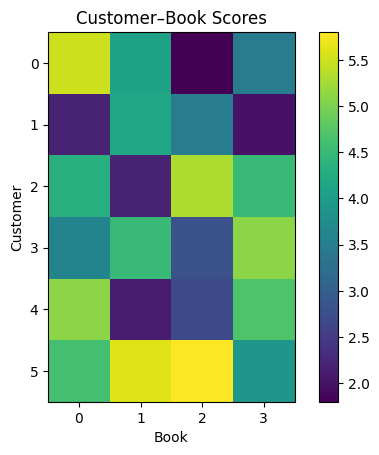

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Vector and Matrix Operations
C = np.array([[5,2,0,1,3],[1,4,2,0,2],[3,1,5,2,0],[0,2,1,5,4],[4,0,2,3,1],[2,3,4,1,5]], dtype=float) # 6 customers x 5 genres
B = np.array([[0.8,0.2,0.1,0.4],[0.1,0.7,0.3,0.2],[0.2,0.1,0.9,0.3],[0.4,0.2,0.1,0.8],[0.3,0.5,0.2,0.1]]) # 5 genres x 4 books
print("Dot product:", np.dot(C[0], B[:,0]))
scores = C @ B
print("Score matrix (customers x books):\n", scores)
print("Transpose shape:", C.T.shape)
print("Element-wise square:\n", C**2)
# Inverse is demonstrated on a valid square matrix
M = np.array([[4.,1.],[2.,3.]])
print("Inverse:\n", np.linalg.inv(M))
norm = np.linalg.norm(C, axis=1, keepdims=True)
Cn = C / norm
sim = Cn @ Cn.T
print("Cosine similarity:\n", np.round(sim,3))
i,j = np.unravel_index(np.triu(sim,1).argmax(), sim.shape)
print("Most similar customers:", i+1, "and", j+1)
x, W, b = C[0], B.T, np.array([0.1,0.2,0.1,0.3])
print("Dense layer y=Wx+b:", W @ x + b)
plt.imshow(scores, cmap="viridis"); plt.colorbar(); plt.xlabel("Book"); plt.ylabel("Customer"); plt.title("Customer–Book Scores"); plt.show()

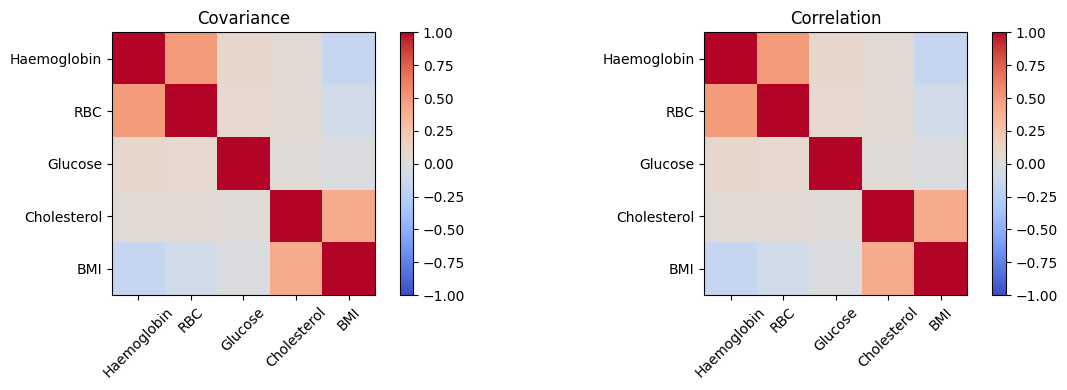

Eigenvalues: [1.58353324 1.3811614  0.97936596 0.58342463 0.49764041]
Variance %: [31.51 27.49 19.49 11.61  9.9 ]


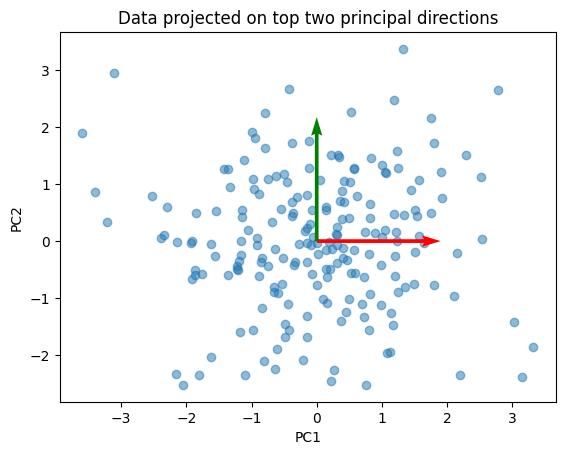

In [2]:
# 2. Covariance, Eigenvalues and Eigenvectors
import pandas as pd
from sklearn.preprocessing import StandardScaler

n=200
df=pd.DataFrame({"Haemoglobin":np.random.normal(13,1.5,n),"RBC":np.random.normal(4.8,.5,n),
"Glucose":np.random.normal(100,15,n),"Cholesterol":np.random.normal(190,25,n),"BMI":np.random.normal(25,4,n)})
df["RBC"] += (df["Haemoglobin"]-13)*.15
df["Cholesterol"] += (df["BMI"]-25)*2
X=StandardScaler().fit_transform(df)
cov=np.cov(X,rowvar=False); corr=np.corrcoef(X,rowvar=False)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,mat,title in zip(ax,[cov,corr],["Covariance","Correlation"]):
 im=a.imshow(mat,cmap="coolwarm",vmin=-1,vmax=1); a.set_title(title); a.set_xticks(range(5),df.columns,rotation=45); a.set_yticks(range(5),df.columns); fig.colorbar(im,ax=a)
plt.tight_layout(); plt.show()
vals,vecs=np.linalg.eigh(cov); order=np.argsort(vals)[::-1]; vals,vecs=vals[order],vecs[:,order]
var=vals/vals.sum()*100
print("Eigenvalues:",vals); print("Variance %:",np.round(var,2))
Z=X@vecs[:,:2]
plt.scatter(Z[:,0],Z[:,1],alpha=.5); plt.quiver(0,0,1,0,color="red",scale=4); plt.quiver(0,0,0,1,color="green",scale=4)
plt.title("Data projected on top two principal directions"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

Observed entropy: 1.4854752972273346
Model 1 Cross entropy: 1.5158759159163444 KL: 0.030400618689010048 H+KL: 1.5158759159163446
Model 2 Cross entropy: 1.6124543443825532 KL: 0.12697904715521868 H+KL: 1.6124543443825532
KL(p||q1): 0.030400618689010048 KL(q1||p): 0.02980641715000123


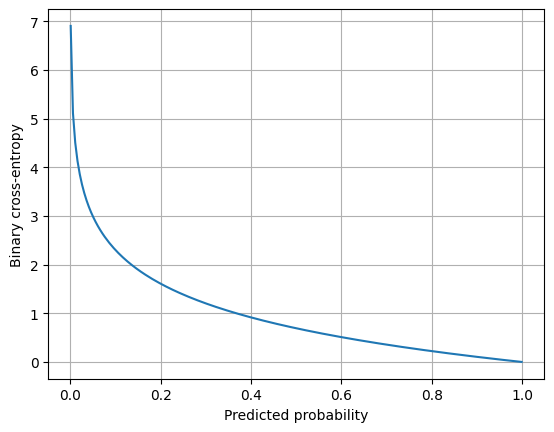

In [4]:

# 4. Entropy, cross entropy and KL divergence
from scipy.special import xlogy
p=np.array([.5,.3,.2]) # Sunny, Cloudy, Rainy observed distribution
q1=np.array([.6,.25,.15]); q2=np.array([.3,.4,.3])
def H(a): return -np.sum(xlogy(a,a))/np.log(2)
def CE(p,q): return -np.sum(p*np.log2(q))
def KL(p,q): return np.sum(p*np.log2(p/q))
print("Observed entropy:",H(p))
for name,q in [("Model 1",q1),("Model 2",q2)]:
 print(name,"Cross entropy:",CE(p,q),"KL:",KL(p,q),"H+KL:",H(p)+KL(p,q))
print("KL(p||q1):",KL(p,q1),"KL(q1||p):",KL(q1,p))
y=1; pred=np.linspace(.001,.999,200); loss=-(y*np.log(pred)+(1-y)*np.log(1-pred))
plt.plot(pred,loss); plt.xlabel("Predicted probability"); plt.ylabel("Binary cross-entropy"); plt.grid(); plt.show()

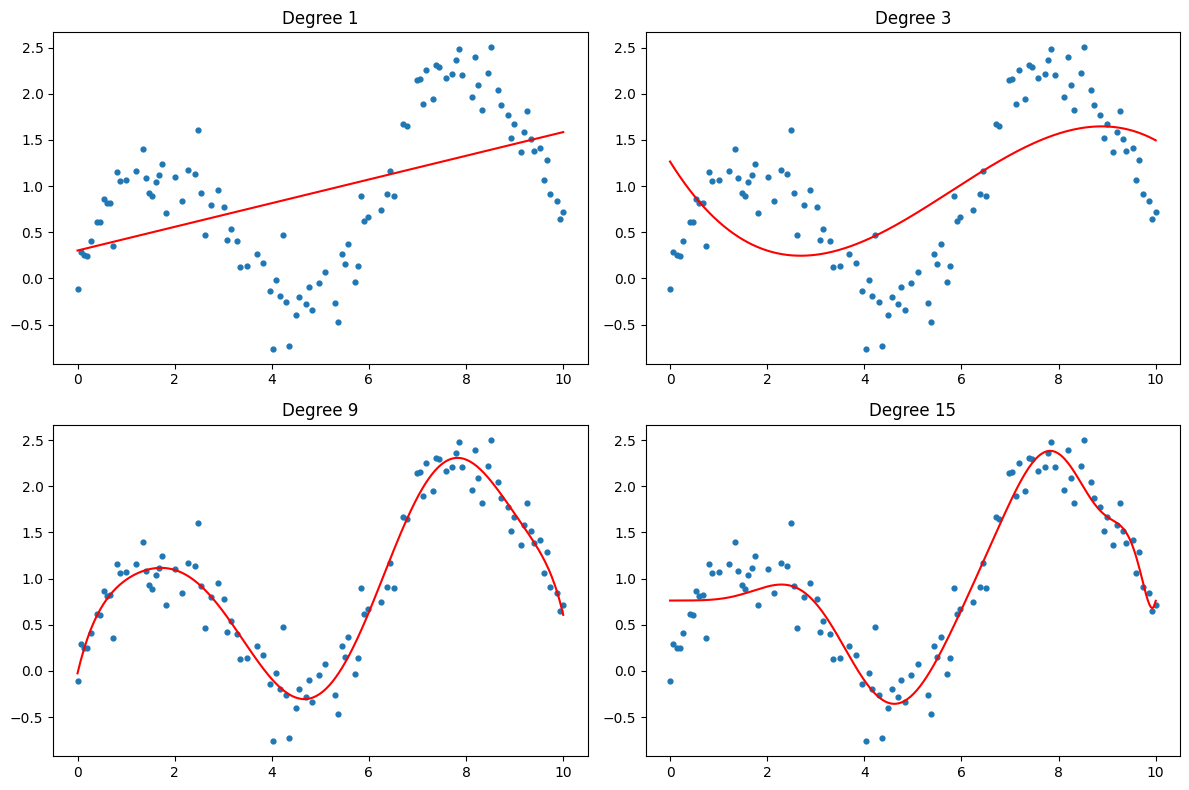

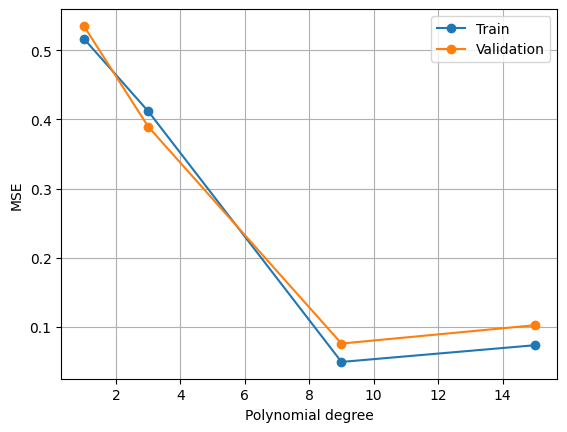

   degree  train_MSE  validation_MSE
0       1   0.516879        0.535250
1       3   0.411752        0.389437
2       9   0.049113        0.075720
3      15   0.073261        0.102183
Prediction variance: 0.0057138443623682925 Estimated bias^2: 0.7278675650255264


In [5]:
# 5. Polynomial regression: underfit / good fit / overfit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
x=np.linspace(0,10,150); y=np.sin(x)+.15*x+np.random.normal(0,.25,150)
X=x.reshape(-1,1); Xtr,Xv,ytr,yv=train_test_split(X,y,test_size=.3,random_state=1)
degrees=[1,3,9,15]; train_err=[]; val_err=[]
fig,axs=plt.subplots(2,2,figsize=(12,8))
for d,ax in zip(degrees,axs.flat):
 model=make_pipeline(PolynomialFeatures(d),LinearRegression()).fit(Xtr,ytr)
 grid=np.linspace(0,10,300).reshape(-1,1)
 ax.scatter(Xtr,ytr,s=12); ax.plot(grid,model.predict(grid),color="red"); ax.set_title(f"Degree {d}")
 train_err.append(mean_squared_error(ytr,model.predict(Xtr))); val_err.append(mean_squared_error(yv,model.predict(Xv)))
plt.tight_layout(); plt.show()
plt.plot(degrees,train_err,"o-",label="Train"); plt.plot(degrees,val_err,"o-",label="Validation")
plt.xlabel("Polynomial degree"); plt.ylabel("MSE"); plt.legend(); plt.grid(); plt.show()
print(pd.DataFrame({"degree":degrees,"train_MSE":train_err,"validation_MSE":val_err}))
# Resampling estimate of prediction variance and squared bias at x=5
preds=[]
for seed in range(30):
 ids=np.random.RandomState(seed).choice(len(X),len(X),replace=True)
 m=make_pipeline(PolynomialFeatures(3),LinearRegression()).fit(X[ids],y[ids])
 preds.append(m.predict([[5]])[0])
print("Prediction variance:",np.var(preds),"Estimated bias^2:",(np.mean(preds)-(np.sin(5)+.75))**2)

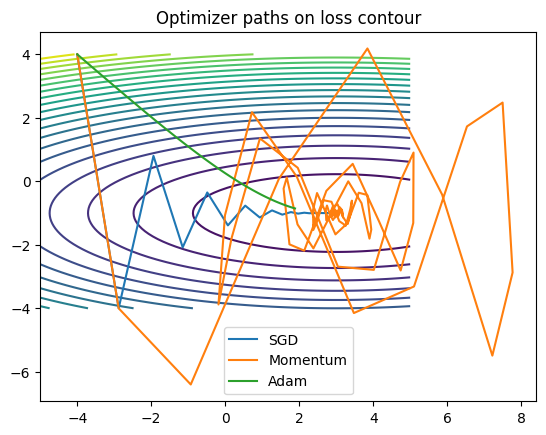

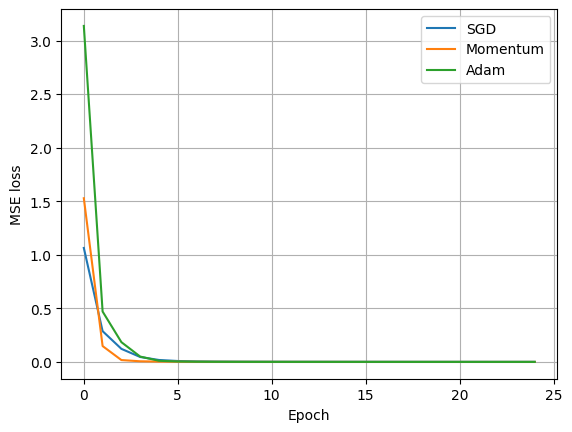

In [6]:
# 6. Optimizer comparison
def grad(w): return np.array([2*(w[0]-3), 20*(w[1]+1)])
def run(opt,lr=.08,steps=100):
 w=np.array([-4.,4.]); m=np.zeros(2); v=np.zeros(2); path=[w.copy()]
 for t in range(1,steps+1):
  g=grad(w)
  if opt=="SGD": w-=lr*g
  elif opt=="Momentum": m=.9*m+g; w-=lr*m
  else:
   m=.9*m+.1*g; v=.999*v+.001*g*g
   w-=lr*(m/(1-.9**t))/(np.sqrt(v/(1-.999**t))+1e-8)
  path.append(w.copy())
 return np.array(path)
xx,yy=np.meshgrid(np.linspace(-5,5,100),np.linspace(-4,4,100)); zz=(xx-3)**2+10*(yy+1)**2
plt.contour(xx,yy,zz,levels=25)
for opt in ["SGD","Momentum","Adam"]:
 path=run(opt); plt.plot(path[:,0],path[:,1],label=opt)
plt.legend(); plt.title("Optimizer paths on loss contour"); plt.show()
# Same Keras regression model with three optimizers
import tensorflow as tf
tf.random.set_seed(42)
X=np.random.rand(1000,4).astype("float32"); y=(3*X[:,0]+2*X[:,1]-X[:,2]+.5*X[:,3]).astype("float32")
histories={}
for name,opt in [("SGD",tf.keras.optimizers.SGD(.03)),("Momentum",tf.keras.optimizers.SGD(.03,momentum=.9)),("Adam",tf.keras.optimizers.Adam(.01))]:
 model=tf.keras.Sequential([tf.keras.layers.Input((4,)),tf.keras.layers.Dense(16,activation="relu"),tf.keras.layers.Dense(1)])
 model.compile(optimizer=opt,loss="mse")
 h=model.fit(X,y,epochs=25,batch_size=32,verbose=0,validation_split=.2); histories[name]=h.history["loss"]
for k,v in histories.items(): plt.plot(v,label=k)
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.grid(); plt.show()

Weights: [0.13310707 0.10443394] Bias: -0.1 Accuracy: 1.0


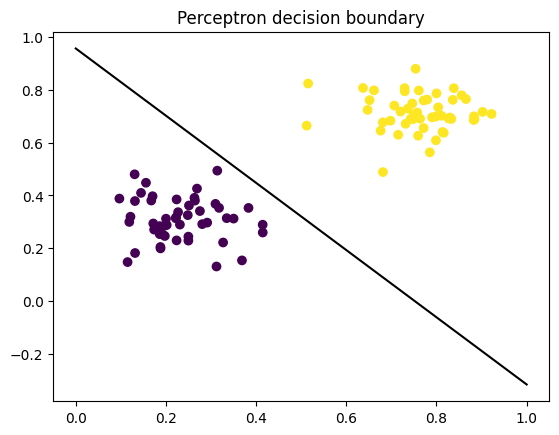

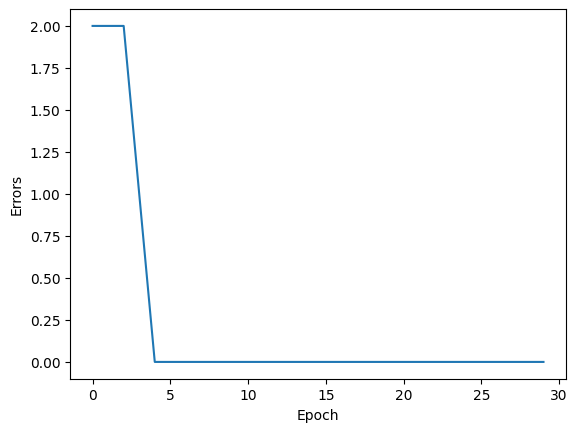

XOR predictions: [1 1 0 0] Target: [0 1 1 0] (single perceptron cannot solve XOR)
step [0 0 1 1 1] sigmoid [0.11920292 0.26894142 0.5        0.73105858 0.88079708] ReLU [0. 0. 0. 1. 2.]


In [7]:
# 7. Perceptron on linearly separable loan-like data and XOR
def step(z): return (z>=0).astype(int)
rng=np.random.default_rng(4); X=np.vstack([rng.normal([.25,.3],.08,(50,2)),rng.normal([.75,.7],.08,(50,2))])
y=np.r_[np.zeros(50),np.ones(50)].astype(int)
w=np.zeros(2); b=0.; lr=.1; updates=[]
for ep in range(30):
 err=0
 for xi,yi in zip(X,y):
  pred=step(xi@w+b); delta=yi-pred
  w+=lr*delta*xi; b+=lr*delta; err+=abs(delta)
 updates.append(err)
print("Weights:",w,"Bias:",b,"Accuracy:",(step(X@w+b)==y).mean())
xx=np.linspace(0,1,100); yy=-(w[0]*xx+b)/(w[1]+1e-9)
plt.scatter(X[:,0],X[:,1],c=y); plt.plot(xx,yy,"k"); plt.title("Perceptron decision boundary"); plt.show()
plt.plot(updates); plt.xlabel("Epoch"); plt.ylabel("Errors"); plt.show()
Xxor=np.array([[0,0],[0,1],[1,0],[1,1]]); yxor=np.array([0,1,1,0]); w=np.zeros(2); b=0
for ep in range(20):
 for xi,yi in zip(Xxor,yxor):
  d=yi-step(xi@w+b); w+=.1*d*xi; b+=.1*d
print("XOR predictions:",step(Xxor@w+b),"Target:",yxor,"(single perceptron cannot solve XOR)")
z=np.array([-2.,-1.,0.,1.,2.]); print("step",step(z),"sigmoid",1/(1+np.exp(-z)),"ReLU",np.maximum(0,z))

Predictions:
 [[0.009]
 [0.985]
 [0.984]
 [0.019]]


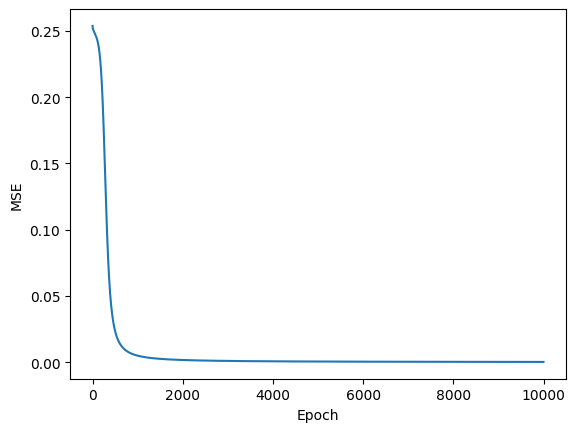

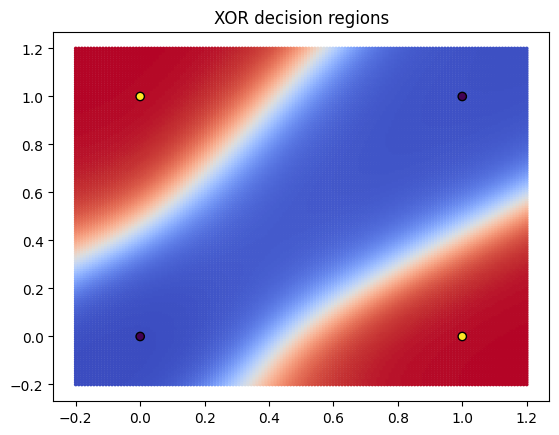

Numerical gradient W2[0,0]: -2.9129195290664847e-05


In [8]:

# 8. Two-layer neural network from scratch for XOR
X=np.array([[0,0],[0,1],[1,0],[1,1]],float); y=np.array([[0],[1],[1],[0]],float)
sig=lambda z:1/(1+np.exp(-np.clip(z,-40,40)))
rng=np.random.default_rng(2); W1=rng.normal(0,1,(2,4)); b1=np.zeros((1,4)); W2=rng.normal(0,1,(4,1)); b2=np.zeros((1,1))
losses=[]; lr=1.0
for ep in range(10000):
 h=sig(X@W1+b1); out=sig(h@W2+b2); loss=np.mean((out-y)**2); losses.append(loss)
 d2=(out-y)*out*(1-out)*2/len(X); dW2=h.T@d2; db2=d2.sum(0,keepdims=True)
 d1=(d2@W2.T)*h*(1-h); dW1=X.T@d1; db1=d1.sum(0,keepdims=True)
 W2-=lr*dW2; b2-=lr*db2; W1-=lr*dW1; b1-=lr*db1
print("Predictions:\n",np.round(out,3))
plt.plot(losses); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.show()
grid=np.array([[a,b] for a in np.linspace(-.2,1.2,150) for b in np.linspace(-.2,1.2,150)])
probs=sig(grid@W1+b1@np.ones((1,4)) if False else grid@W1+b1); probs=sig(probs@W2+b2)
plt.scatter(grid[:,0],grid[:,1],c=probs.ravel(),s=3,cmap="coolwarm"); plt.scatter(X[:,0],X[:,1],c=y.ravel(),edgecolors="black"); plt.title("XOR decision regions"); plt.show()
# Numerical gradient check for W2[0,0]
idx=(0,0); eps=1e-5; old=W2[idx]
def calc_loss():
 return np.mean((sig(sig(X@W1+b1)@W2+b2)-y)**2)
W2[idx]=old+eps; lp=calc_loss(); W2[idx]=old-eps; lm=calc_loss(); W2[idx]=old
print("Numerical gradient W2[0,0]:",(lp-lm)/(2*eps))


              precision    recall  f1-score   support

           0       0.68      0.59      0.63       122
           1       0.63      0.71      0.67       118

    accuracy                           0.65       240
   macro avg       0.65      0.65      0.65       240
weighted avg       0.65      0.65      0.65       240

Confusion matrix:
 [[72 50]
 [34 84]]


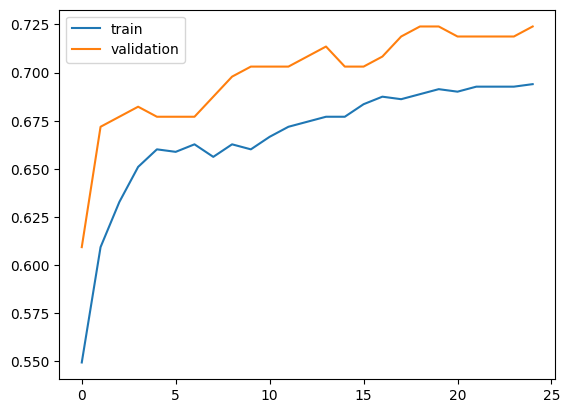

Hidden units 8 test accuracy 0.6041666865348816
Hidden units 32 test accuracy 0.6583333611488342
Hidden units 64 test accuracy 0.6625000238418579


In [9]:
# 9. MLP churn classification with synthetic customer data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
n=1200
df=pd.DataFrame({"tenure":np.random.randint(1,72,n),"monthly_charges":np.random.uniform(20,120,n),
 "contract":np.random.choice(["Month","Year","TwoYear"],n),"complaints":np.random.poisson(1,n),"data_usage":np.random.uniform(1,100,n)})
logit=-2+.025*(70-df.tenure)+.018*(df.monthly_charges-60)+.5*df.complaints+(df.contract=="Month")*1.0
df["Churn"]=(np.random.rand(n)<1/(1+np.exp(-logit))).astype(int)
X=pd.get_dummies(df.drop(columns="Churn"),drop_first=True); y=df.Churn
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=42)
sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xte=sc.transform(Xte)
import tensorflow as tf
model=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(32,activation="relu"),tf.keras.layers.Dense(16,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
h=model.fit(Xtr,ytr,epochs=25,batch_size=32,validation_split=.2,verbose=0)
pred=(model.predict(Xte,verbose=0).ravel()>.5).astype(int)
print(classification_report(yte,pred)); print("Confusion matrix:\n",confusion_matrix(yte,pred))
plt.plot(h.history["accuracy"],label="train"); plt.plot(h.history["val_accuracy"],label="validation"); plt.legend(); plt.show()
for units in [8,32,64]:
 m=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(units,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
 m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"]); m.fit(Xtr,ytr,epochs=8,verbose=0)
 print("Hidden units",units,"test accuracy",m.evaluate(Xte,yte,verbose=0)[1])

In [13]:
# 12. Compare CNN configurations on CIFAR-10 subset
import tensorflow as tf
import time
import pandas as pd
(xtr,ytr),(xte,yte)=tf.keras.datasets.cifar10.load_data()
xtr=xtr[:8000].astype("float32")/255; ytr=ytr[:8000].ravel()
xte=xte[:1500].astype("float32")/255; yte=yte[:1500].ravel()
def make_cnn(nconv=2,k=3,filters=32,pool="max",bn=False,lr=.001):
 layers=[tf.keras.layers.Input((32,32,3))]
 for i in range(nconv):
  f=filters*(2**min(i,2)); layers.append(tf.keras.layers.Conv2D(f,k,padding="same",use_bias=not bn))
  if bn: layers.append(tf.keras.layers.BatchNormalization())
  layers.append(tf.keras.layers.Activation("relu"))
  layers.append(tf.keras.layers.MaxPooling2D(pool_size=(2,2)) if pool=="max" else tf.keras.layers.AveragePooling2D(pool_size=(2,2)))
 layers += [tf.keras.layers.Flatten(),tf.keras.layers.Dense(64,activation="relu"),tf.keras.layers.Dense(10,activation="softmax")]
 m=tf.keras.Sequential(layers); m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
configs=[(2,3,24,"max",False,.001),(3,3,24,"max",True,.001),(2,5,24,"avg",False,.001)]
rows=[]
for cfg in configs:
 m=make_cnn(*cfg); t=time.time(); m.fit(xtr,ytr,epochs=3,batch_size=64,verbose=0); sec=time.time()-t
 loss,acc=m.evaluate(xte,yte,verbose=0); rows.append([cfg,acc,m.count_params(),sec])
print(pd.DataFrame(rows,columns=["Configuration","Test accuracy","Parameters","Training seconds"]))

 33955840/170498071 ━━━━━━━━━━━━━━━━━━━━ 8:59 4us/step

KeyboardInterrupt: 

MAE: 2.9923198223114014 RMSE: 3.719948327105559


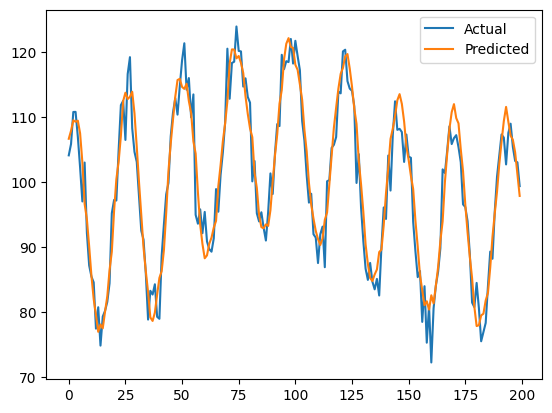

In [14]:
# 13. Time-series windows and SimpleRNN
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

t=np.arange(365*24); series=(100+15*np.sin(2*np.pi*t/24)+8*np.sin(2*np.pi*t/(24*7))+np.random.normal(0,3,len(t))).astype("float32")
sc=MinMaxScaler(); scaled=sc.fit_transform(series.reshape(-1,1)).ravel()
window=24
X=np.array([scaled[i-window:i] for i in range(window,len(scaled))]); y=scaled[window:]
cut=int(.8*len(X)); Xtr,Xte=X[:cut],X[cut:]; ytr,yte=y[:cut],y[cut:]
Xtr=Xtr[...,None]; Xte=Xte[...,None]
m=tf.keras.Sequential([tf.keras.layers.Input((window,1)),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(1)])
m.compile(optimizer="adam",loss="mse"); m.fit(Xtr,ytr,epochs=8,batch_size=64,verbose=0)
p=sc.inverse_transform(m.predict(Xte,verbose=0)); actual=sc.inverse_transform(yte.reshape(-1,1))
print("MAE:",mean_absolute_error(actual,p),"RMSE:",np.sqrt(mean_squared_error(actual,p)))
plt.plot(actual[:200],label="Actual"); plt.plot(p[:200],label="Predicted"); plt.legend(); plt.show()

Manual hidden states:
 [[-0.1445  0.1267 -0.0836]
 [-0.2513  0.4328 -0.1021]
 [ 0.0727  0.3376  0.3402]
 [-0.5999  0.2951  0.0896]
 [ 0.2353  0.3563  0.2277]]
Keras hidden states:
 [[-0.1445  0.1267 -0.0836]
 [-0.2513  0.4328 -0.1021]
 [ 0.0727  0.3376  0.3402]
 [-0.5999  0.2951  0.0896]
 [ 0.2353  0.3563  0.2277]]


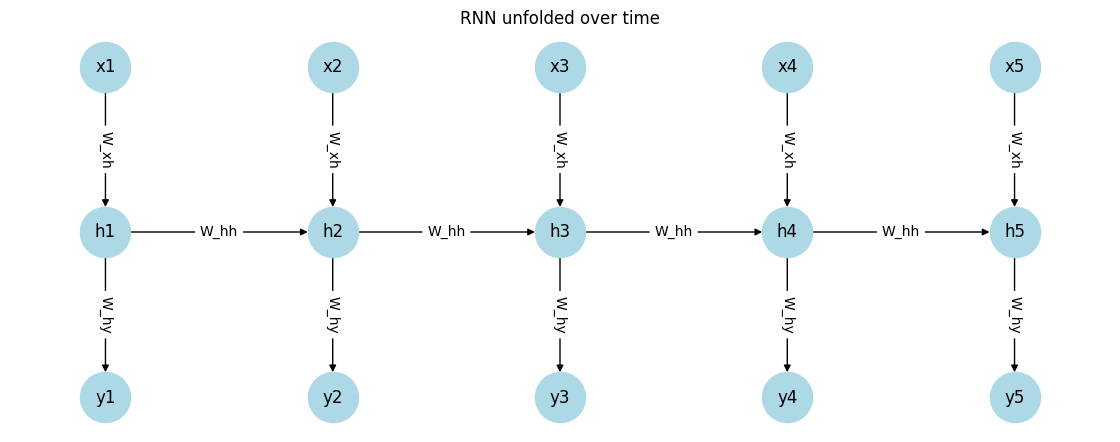

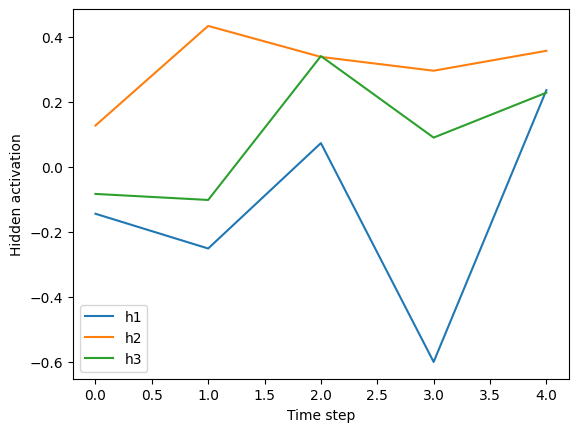

In [15]:
# 14. Unroll a SimpleRNN across five time steps
import tensorflow as tf, networkx as nx
seq=np.array([[[.2],[.5],[.1],[.8],[.4]]],dtype="float32")
rnn=tf.keras.layers.SimpleRNN(3,return_sequences=True,return_state=True)
out,state=rnn(seq); wx,wh,b=rnn.get_weights()
h=np.zeros(3); states=[]
for xt in seq[0]:
 h=np.tanh(xt@wx+h@wh+b); states.append(h.copy())
print("Manual hidden states:\n",np.round(states,4))
print("Keras hidden states:\n",np.round(out.numpy()[0],4))
G=nx.DiGraph()
for i in range(1,6):
 G.add_node(f"x{i}",pos=(i,2)); G.add_node(f"h{i}",pos=(i,1)); G.add_node(f"y{i}",pos=(i,0))
 G.add_edge(f"x{i}",f"h{i}",label="W_xh"); G.add_edge(f"h{i}",f"y{i}",label="W_hy")
 if i>1:G.add_edge(f"h{i-1}",f"h{i}",label="W_hh")
pos=nx.get_node_attributes(G,"pos"); plt.figure(figsize=(11,4)); nx.draw(G,pos,with_labels=True,node_size=1300,node_color="lightblue",arrows=True)
nx.draw_networkx_edge_labels(G,pos,edge_labels=nx.get_edge_attributes(G,"label")); plt.title("RNN unfolded over time"); plt.show()
plt.plot(np.array(states)); plt.xlabel("Time step"); plt.ylabel("Hidden activation"); plt.legend(["h1","h2","h3"]); plt.show()


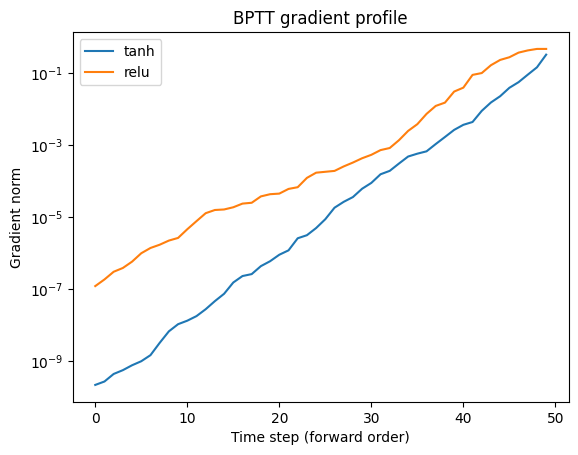

Small gradients indicate vanishing; very large gradients indicate exploding gradients.


In [16]:
# 15. Gradient magnitude through recurrent time steps
import tensorflow as tf
def gradient_profile(act,steps):
 cell=tf.keras.layers.SimpleRNNCell(16,activation=act)
 xs=tf.random.normal((1,steps,8)); h=tf.zeros((1,16)); states=[]
 with tf.GradientTape(persistent=True) as tape:
  tape.watch(xs)
  for t in range(steps):
   h,_=cell(xs[:,t,:],[h]); tape.watch(h); states.append(h)
  loss=tf.reduce_mean(states[-1]**2)
 norms=[float(tf.linalg.norm(tape.gradient(loss,s))) if tape.gradient(loss,s) is not None else 0 for s in states]
 del tape
 return norms
for act in ["tanh","relu"]:
 plt.plot(gradient_profile(act,50),label=act)
plt.yscale("log"); plt.xlabel("Time step (forward order)"); plt.ylabel("Gradient norm"); plt.legend(); plt.title("BPTT gradient profile"); plt.show()
print("Small gradients indicate vanishing; very large gradients indicate exploding gradients.")


       Model       MAE      RMSE    MAPE %   Seconds  Train loss  Val loss
0  SimpleRNN  2.204897  2.693052  2.220007  6.628992    0.001704  0.002447
1       LSTM  7.686971  8.679605  7.896247  5.677769    0.021540  0.022083


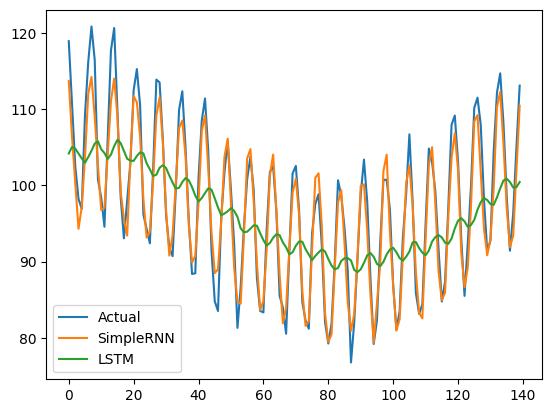

In [17]:
# 16. Compare SimpleRNN and LSTM forecasts
import tensorflow as tf
t=np.arange(730); s=(80+12*np.sin(2*np.pi*t/7)+.03*t+10*np.sin(2*np.pi*t/180)+np.random.normal(0,2,730)).astype("float32")
sc=MinMaxScaler(); z=sc.fit_transform(s[:,None]).ravel(); w=30
X=np.array([z[i-w:i] for i in range(w,len(z))])[...,None]; y=z[w:]
cut=int(.8*len(X)); Xtr,Xte,ytr,yte=X[:cut],X[cut:],y[:cut],y[cut:]
rows=[]; forecasts={}
for typ in ["SimpleRNN","LSTM"]:
 layer=tf.keras.layers.SimpleRNN(32) if typ=="SimpleRNN" else tf.keras.layers.LSTM(32)
 m=tf.keras.Sequential([tf.keras.layers.Input((w,1)),layer,tf.keras.layers.Dense(1)])
 m.compile(optimizer="adam",loss="mse"); start=time.time(); h=m.fit(Xtr,ytr,validation_split=.2,epochs=10,batch_size=32,verbose=0); secs=time.time()-start
 p=sc.inverse_transform(m.predict(Xte,verbose=0)); a=sc.inverse_transform(yte[:,None]); forecasts[typ]=p.ravel()
 mae=mean_absolute_error(a,p); rmse=np.sqrt(mean_squared_error(a,p)); mape=np.mean(np.abs((a-p)/np.maximum(a,1e-6)))*100
 rows.append([typ,mae,rmse,mape,secs,h.history["loss"][-1],h.history["val_loss"][-1]])
print(pd.DataFrame(rows,columns=["Model","MAE","RMSE","MAPE %","Seconds","Train loss","Val loss"]))
plt.plot(a[:150],label="Actual"); [plt.plot(v[:150],label=k) for k,v in forecasts.items()]; plt.legend(); plt.show()

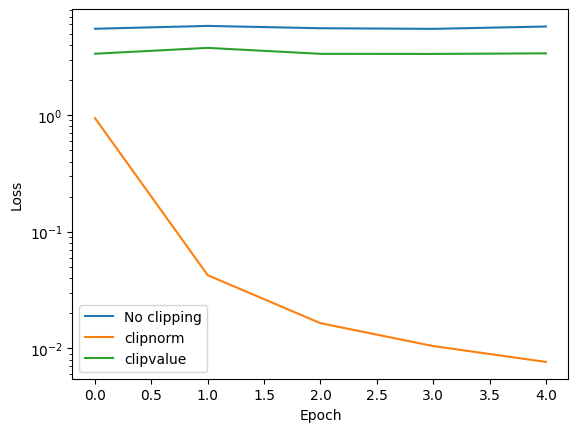

   No clipping  clipnorm  clipvalue
0     5.515919  0.942653   3.366195
1     5.832441  0.042307   3.779458
2     5.571706  0.016399   3.359592
3     5.503749  0.010431   3.353102
4     5.764714  0.007626   3.392575


In [18]:
# 17. Character-level RNN with gradient clipping comparison
import tensorflow as tf
text_data=("deep learning models learn patterns from data. ")*100
chars=sorted(set(text_data)); to_id={c:i for i,c in enumerate(chars)}
ids=np.array([to_id[c] for c in text_data]); seq=40
X=np.array([ids[i:i+seq] for i in range(len(ids)-seq-1)]); y=ids[seq+1:len(ids)]
X=tf.keras.utils.to_categorical(X,len(chars)); y=tf.keras.utils.to_categorical(y,len(chars))
X=X[:3000]; y=y[:3000]
histories={}
for name,opt in [("No clipping",tf.keras.optimizers.SGD(learning_rate=1.0)),("clipnorm",tf.keras.optimizers.SGD(learning_rate=1.0,clipnorm=1.0)),("clipvalue",tf.keras.optimizers.SGD(learning_rate=1.0,clipvalue=.5))]:
 m=tf.keras.Sequential([tf.keras.layers.Input((seq,len(chars))),tf.keras.layers.SimpleRNN(32),tf.keras.layers.Dense(len(chars),activation="softmax")])
 m.compile(optimizer=opt,loss="categorical_crossentropy"); h=m.fit(X,y,epochs=5,batch_size=64,verbose=0); histories[name]=h.history["loss"]
for k,v in histories.items(): plt.plot(v,label=k)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.yscale("log"); plt.show()
print(pd.DataFrame(histories))

In [19]:
# 18. KerasTuner search on IMDB reviews (compact run)
!pip -q install keras-tuner
import tensorflow as tf, keras_tuner as kt, time
vocab=10000; maxlen=120
(xtr,ytr),(xte,yte)=tf.keras.datasets.imdb.load_data(num_words=vocab)
xtr=tf.keras.preprocessing.sequence.pad_sequences(xtr[:8000],maxlen=maxlen)
ytr=ytr[:8000]; xte=tf.keras.preprocessing.sequence.pad_sequences(xte[:2000],maxlen=maxlen); yte=yte[:2000]
def build_model(hp):
 cell=hp.Choice("cell",["SimpleRNN","LSTM","GRU"]); units=hp.Choice("units",[32,64])
 inp=tf.keras.Input((maxlen,)); x=tf.keras.layers.Embedding(vocab,hp.Choice("embed",[32,64]))(inp)
 layer={"SimpleRNN":tf.keras.layers.SimpleRNN,"LSTM":tf.keras.layers.LSTM,"GRU":tf.keras.layers.GRU}[cell]
 x=layer(units)(x); x=tf.keras.layers.Dropout(hp.Choice("dropout",[.2,.4]))(x)
 out=tf.keras.layers.Dense(1,activation="sigmoid")(x); m=tf.keras.Model(inp,out)
 m.compile(optimizer=tf.keras.optimizers.Adam(hp.Choice("lr",[.001,.0003])),loss="binary_crossentropy",metrics=["accuracy"]); return m
tuner=kt.RandomSearch(build_model,objective="val_accuracy",max_trials=3,directory="kt_dir",project_name="rnn_lab",overwrite=True)
tuner.search(xtr,ytr,validation_split=.2,epochs=2,batch_size=128,verbose=1)
best=tuner.get_best_models(1)[0]; print("Best hyperparameters:",tuner.get_best_hyperparameters(1)[0].values)
print("Test results:",best.evaluate(xte,yte,verbose=0),"Parameters:",best.count_params())

Trial 3 Complete [00h 00m 29s]
val_accuracy: 0.6743749976158142

Best val_accuracy So Far: 0.8118749856948853
Total elapsed time: 00h 01m 14s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best hyperparameters: {'cell': 'LSTM', 'units': 64, 'embed': 64, 'dropout': 0.2, 'lr': 0.001}
Test results: [0.4637179672718048, 0.7960000038146973] Parameters: 673089


Components for 95% variance: 29
Sklearn explained variance: 0.9547965245651595


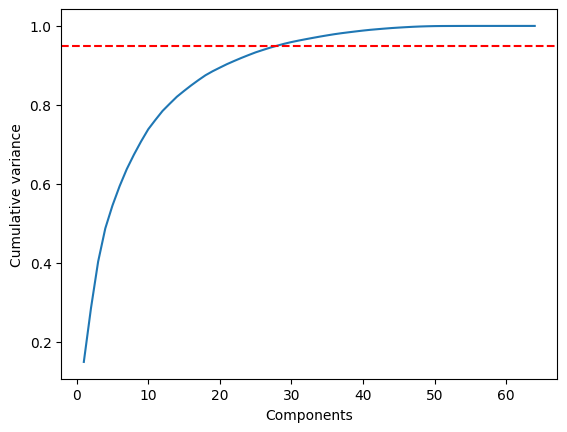

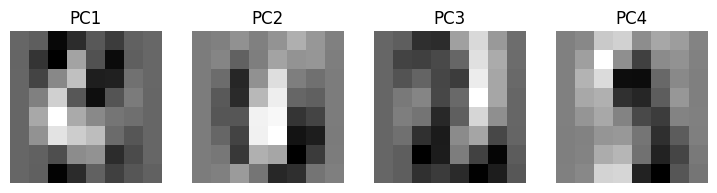

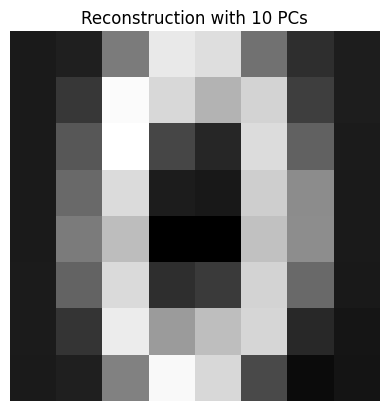

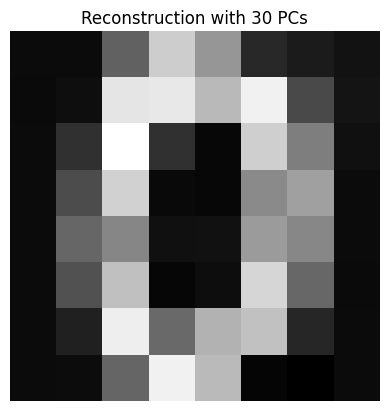

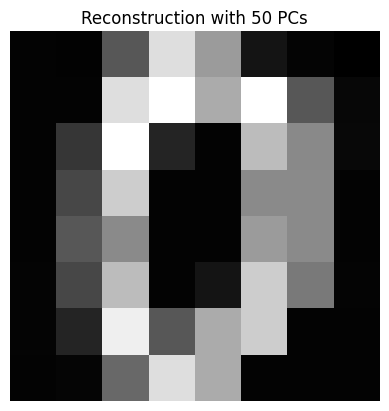

In [20]:
# 19. PCA from scratch and sklearn verification using digits
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
digits=load_digits(); X=digits.data; Xc=X-X.mean(0)
cov=np.cov(Xc,rowvar=False); vals,vecs=np.linalg.eigh(cov); idx=np.argsort(vals)[::-1]; vals,vecs=vals[idx],vecs[:,idx]
ratio=vals/vals.sum(); cum=np.cumsum(ratio); k=np.argmax(cum>=.95)+1
print("Components for 95% variance:",k)
pca=PCA(n_components=k).fit(X); print("Sklearn explained variance:",pca.explained_variance_ratio_.sum())
plt.plot(np.arange(1,len(cum)+1),cum); plt.axhline(.95,color="red",ls="--"); plt.xlabel("Components"); plt.ylabel("Cumulative variance"); plt.show()
fig,ax=plt.subplots(1,4,figsize=(9,3))
for a,i in zip(ax,range(4)): a.imshow(vecs[:,i].reshape(8,8),cmap="gray"); a.set_title(f"PC{i+1}"); a.axis("off")
plt.show()
for ncomp in [10,30,50]:
 pp=PCA(n_components=ncomp).fit(X); rec=pp.inverse_transform(pp.transform(X[:1]))
 plt.figure(); plt.imshow(rec.reshape(8,8),cmap="gray"); plt.title(f"Reconstruction with {ncomp} PCs"); plt.axis("off"); plt.show()


Components 1 noise variance estimate 1.7581396520890387 reconstruction MSE 1.4036986982278887
Components 2 noise variance estimate 0.1707545068152607 reconstruction MSE 0.10224779868097834
Components 3 noise variance estimate 0.16070140331086316 reconstruction MSE 0.06415200020169662
Components 4 noise variance estimate 0.1556674019825911 reconstruction MSE 0.031071213435725116


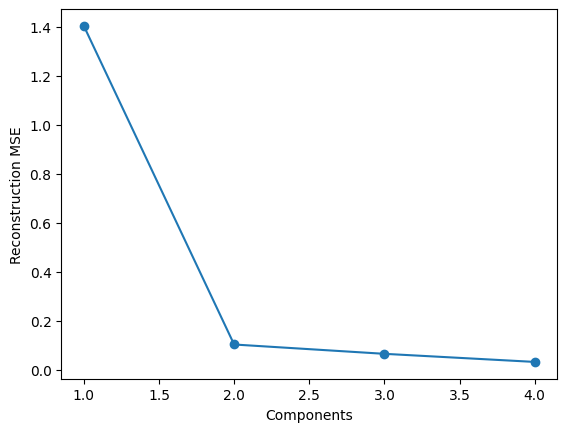

Generated synthetic sensor readings:
 [[-1.08 -0.53 -0.66  1.66  1.18]
 [ 0.24 -0.07  0.58 -0.66  0.38]
 [-0.31  0.07 -0.62  0.72 -0.44]
 [ 0.37 -0.02  0.68 -0.87  0.27]
 [-0.56 -0.29 -0.3   0.83  0.67]]
PPCA model: x = Wz + mu + epsilon, where epsilon represents Gaussian noise.


In [21]:
# 20. PPCA-style model using sklearn PCA noise variance
from sklearn.decomposition import PCA
n=500; latent=np.random.normal(size=(n,2)); W=np.random.normal(size=(2,5))
X=latent@W+np.random.normal(0,.4,(n,5)); X[::25,2]=np.nan
X=np.nan_to_num(X,nan=np.nanmean(X,axis=0)[2])
errs=[]
for k in range(1,5):
 p=PCA(n_components=k).fit(X); rec=p.inverse_transform(p.transform(X))
 errs.append(np.mean((X-rec)**2))
 print("Components",k,"noise variance estimate",p.noise_variance_,"reconstruction MSE",errs[-1])
plt.plot(range(1,5),errs,"o-"); plt.xlabel("Components"); plt.ylabel("Reconstruction MSE"); plt.show()
p=PCA(n_components=2).fit(X); z=p.transform(X); generated=p.inverse_transform(np.random.normal(size=(5,2)))
print("Generated synthetic sensor readings:\n",np.round(generated,2))
print("PPCA model: x = Wz + mu + epsilon, where epsilon represents Gaussian noise.")


           Pay  Benefits  Workload  Stress  Manager  Support  Growth  \
Pay       1.00     -0.05     -0.38    0.52     0.15    -0.51    0.61   
Benefits -0.05      1.00      0.66    0.59     0.80     0.63   -0.66   
Workload -0.38      0.66      1.00    0.51     0.68     0.89   -0.79   
Stress    0.52      0.59      0.51    1.00     0.78     0.38   -0.17   
Manager   0.15      0.80      0.68    0.78     1.00     0.62   -0.62   
Support  -0.51      0.63      0.89    0.38     0.62     1.00   -0.86   
Growth    0.61     -0.66     -0.79   -0.17    -0.62    -0.86    1.00   
Training  0.51     -0.72     -0.78   -0.26    -0.69    -0.84    0.96   
Team     -0.03     -0.36     -0.65   -0.68    -0.43    -0.60    0.25   
Culture  -0.56     -0.48     -0.34   -0.85    -0.65    -0.21    0.05   

          Training  Team  Culture  
Pay           0.51 -0.03    -0.56  
Benefits     -0.72 -0.36    -0.48  
Workload     -0.78 -0.65    -0.34  
Stress       -0.26 -0.68    -0.85  
Manager      -0.69 -0.43   

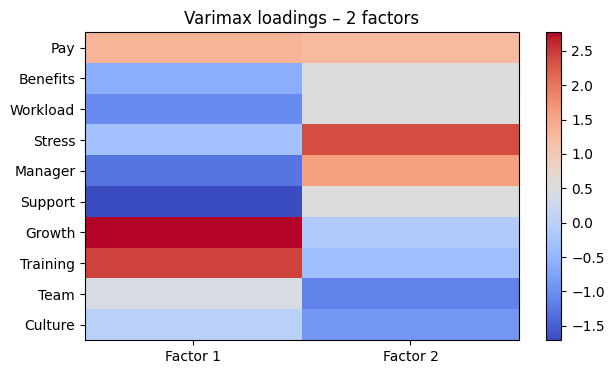

2 factors top loadings:
              0     1
Pay       1.31  1.24
Benefits -0.62  0.50
Workload -1.04  0.54
Stress   -0.31  2.36
Manager  -1.28  1.56
Support  -1.71  0.53
Growth    2.77 -0.13
Training  2.44 -0.35
Team      0.41 -1.14
Culture   0.00 -0.90


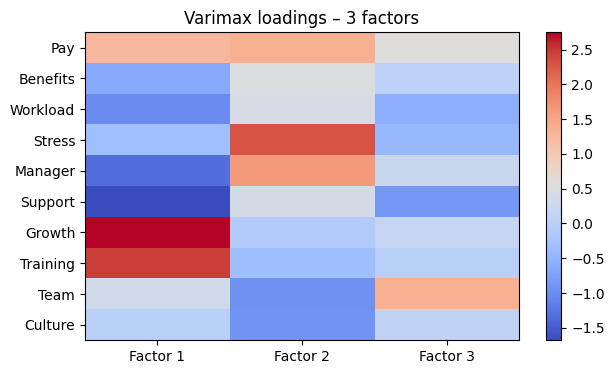

3 factors top loadings:
              0     1     2
Pay       1.27  1.37  0.55
Benefits -0.64  0.51  0.06
Workload -1.02  0.45 -0.56
Stress   -0.31  2.30 -0.45
Manager  -1.33  1.64  0.22
Support  -1.68  0.40 -0.86
Growth    2.75 -0.10  0.16
Training  2.46 -0.34 -0.01
Team      0.34 -0.94  1.37
Culture   0.01 -0.90  0.09


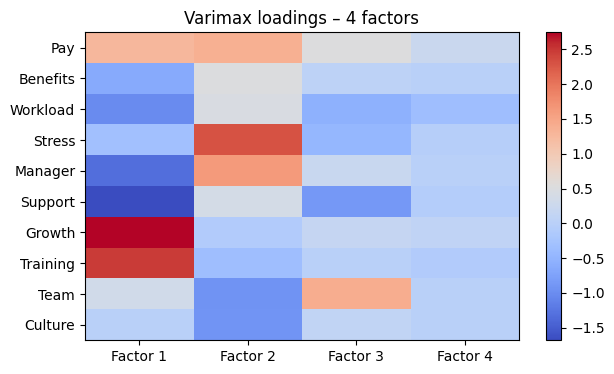

4 factors top loadings:
              0     1     2     3
Pay       1.27  1.38  0.52  0.22
Benefits -0.64  0.51  0.05  0.01
Workload -1.02  0.45 -0.54 -0.34
Stress   -0.31  2.30 -0.46 -0.04
Manager  -1.33  1.64  0.21 -0.00
Support  -1.68  0.39 -0.86 -0.07
Growth    2.74 -0.09  0.15  0.10
Training  2.47 -0.34  0.00 -0.10
Team      0.34 -0.92  1.41  0.01
Culture   0.01 -0.90  0.10 -0.00
PCA explained variance: [0.60262562 0.27796259 0.07596862]


In [22]:
# 21. Factor analysis with varimax rotation
from sklearn.decomposition import FactorAnalysis, PCA
from scipy.linalg import orthogonal_procrustes
n=300
latent=np.random.normal(size=(n,3)); load=np.random.normal(size=(10,3))
X=latent@load.T+np.random.normal(0,.5,(n,10))
cols=["Pay","Benefits","Workload","Stress","Manager","Support","Growth","Training","Team","Culture"]
df=pd.DataFrame(X,columns=cols); print(df.corr().round(2))
def varimax(Phi,gamma=1.0,q=20):
 p,k=Phi.shape; R=np.eye(k)
 for _ in range(q):
  L=Phi@R; u,s,v=np.linalg.svd(Phi.T@(L**3-(gamma/p)*L@np.diag(np.diag(L.T@L))))
  R=u@v
 return Phi@R
for k in [2,3,4]:
 fa=FactorAnalysis(n_components=k,random_state=42).fit(X); L=varimax(fa.components_.T)
 plt.figure(figsize=(7,4)); plt.imshow(L,cmap="coolwarm",aspect="auto"); plt.colorbar()
 plt.xticks(range(k),[f"Factor {i+1}" for i in range(k)]); plt.yticks(range(10),cols); plt.title(f"Varimax loadings – {k} factors"); plt.show()
 print(f"{k} factors top loadings:\n",pd.DataFrame(L,index=cols).round(2))
print("PCA explained variance:",PCA(n_components=3).fit(X).explained_variance_ratio_)


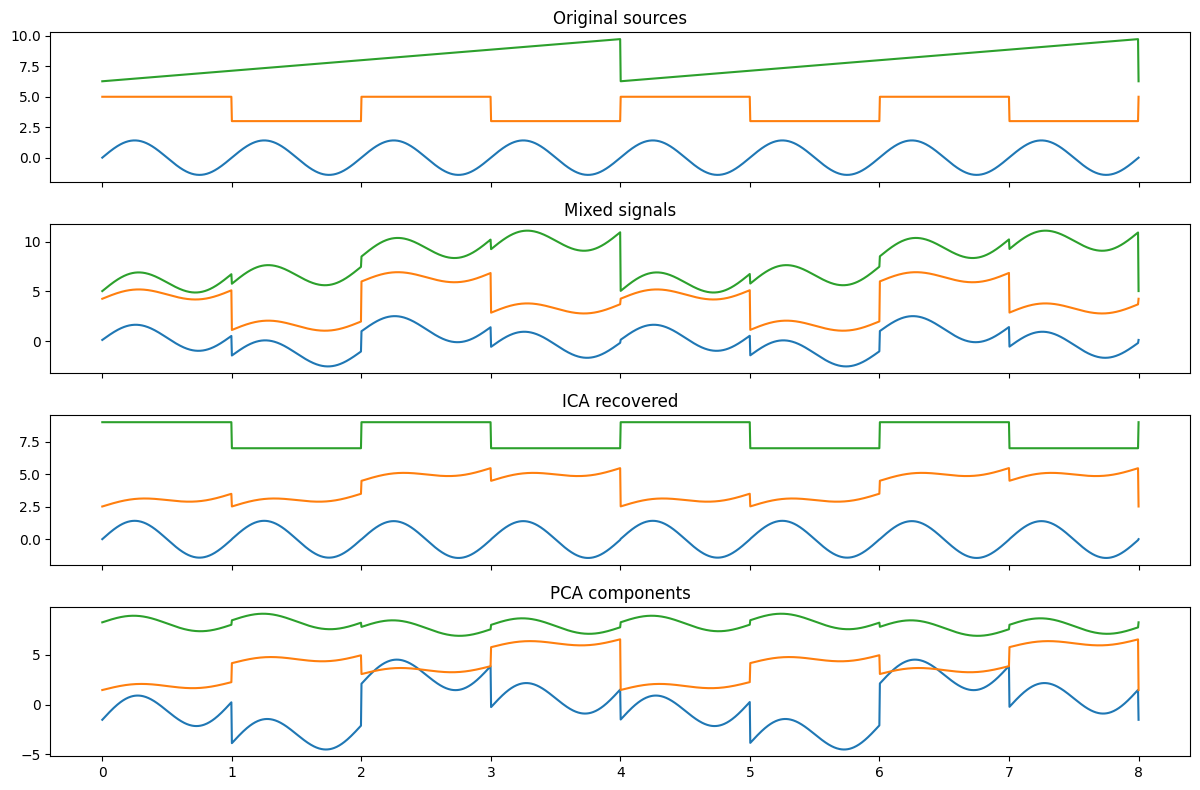

Best absolute correlation for ICA: [1.    1.    0.878]
Best absolute correlation for PCA: [0.91  0.855 0.812]


In [23]:
# 22. ICA versus PCA source separation
from scipy.signal import sawtooth, square
from sklearn.decomposition import FastICA, PCA
t=np.linspace(0,8,2000)
S=np.c_[np.sin(2*np.pi*t),square(2*np.pi*.5*t),sawtooth(2*np.pi*.25*t)]
S=(S-S.mean(0))/S.std(0); A=np.array([[1,1,.5],[.5,2,1],[1,.5,2]])
X=S@A.T
ica=FastICA(n_components=3,random_state=42,max_iter=1000); Si=ica.fit_transform(X)
Sp=PCA(n_components=3).fit_transform(X)
fig,ax=plt.subplots(4,1,figsize=(12,8),sharex=True)
for j in range(3): ax[0].plot(t,S[:,j]+j*4)
for j in range(3): ax[1].plot(t,X[:,j]+j*4)
for j in range(3): ax[2].plot(t,Si[:,j]+j*4)
for j in range(3): ax[3].plot(t,Sp[:,j]+j*4)
for a,title in zip(ax,["Original sources","Mixed signals","ICA recovered","PCA components"]): a.set_title(title)
plt.tight_layout(); plt.show()
def best_corr(A,B):
 return np.max(np.abs(np.corrcoef(A.T,B.T)[:A.shape[1],A.shape[1]:]),axis=1)
print("Best absolute correlation for ICA:",np.round(best_corr(S,Si),3))
print("Best absolute correlation for PCA:",np.round(best_corr(S,Sp),3))


Model valid: True


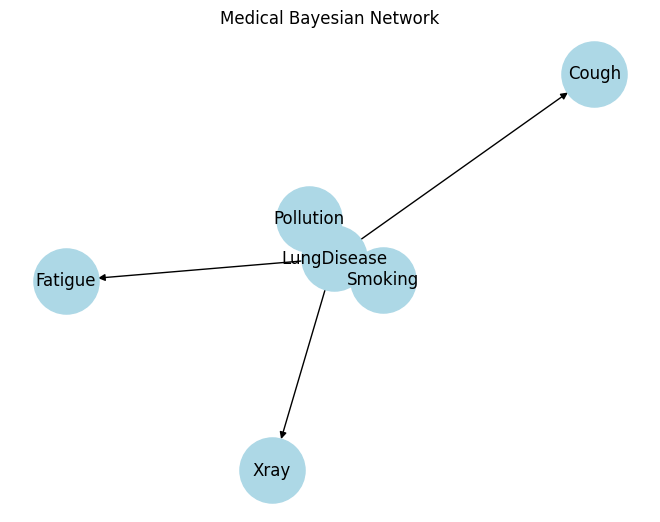

Edges: [('Smoking', 'LungDisease'), ('LungDisease', 'Cough'), ('LungDisease', 'Xray'), ('LungDisease', 'Fatigue'), ('Pollution', 'LungDisease')]
Conditional independence examples: Cough, Xray and Fatigue are conditionally independent given LungDisease.


In [24]:
# 23. Bayesian network with pgmpy
!pip -q install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),
 ("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
cpds=[
 TabularCPD("Smoking",2,[[.7],[.3]]), TabularCPD("Pollution",2,[[.8],[.2]]),
 TabularCPD("LungDisease",2,[[.99,.9,.9,.2],[.01,.1,.1,.8]],evidence=["Smoking","Pollution"],evidence_card=[2,2]),
 TabularCPD("Cough",2,[[.8,.2],[.2,.8]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Xray",2,[[.95,.1],[.05,.9]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Fatigue",2,[[.7,.3],[.3,.7]],evidence=["LungDisease"],evidence_card=[2])]
model.add_cpds(*cpds); print("Model valid:",model.check_model())
G=nx.DiGraph(model.edges()); pos=nx.spring_layout(G,seed=3)
nx.draw(G,pos,with_labels=True,node_color="lightblue",node_size=2200,arrows=True); plt.title("Medical Bayesian Network"); plt.show()
print("Edges:",list(model.edges()))
print("Conditional independence examples: Cough, Xray and Fatigue are conditionally independent given LungDisease.")


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Exact P(LungDisease=1 | Xray=1,Cough=1): 0.8789381097073404
Rejection estimate: 0.877891339429801 accepted: 3718
   Accepted samples  Estimated probability  Absolute error
0               100               0.840000        0.038938
1               500               0.852000        0.026938
2              1000               0.877000        0.001938
3              5000               0.877891        0.001047
4             10000               0.877891        0.001047
5             50000               0.877891        0.001047


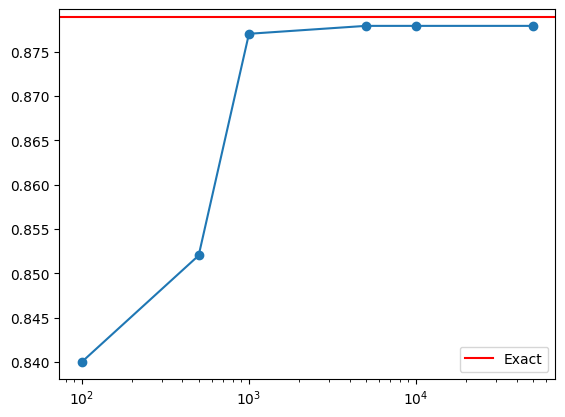

In [25]:
# 24. Exact and approximate Bayesian inference
# Re-create the model from Experiment 23 if running this section independently
!pip -q install pgmpy
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling
model=DiscreteBayesianNetwork([("Smoking","LungDisease"),("Pollution","LungDisease"),("LungDisease","Cough"),("LungDisease","Xray"),("LungDisease","Fatigue")])
model.add_cpds(TabularCPD("Smoking",2,[[.7],[.3]]),TabularCPD("Pollution",2,[[.8],[.2]]),
 TabularCPD("LungDisease",2,[[.99,.9,.9,.2],[.01,.1,.1,.8]],evidence=["Smoking","Pollution"],evidence_card=[2,2]),
 TabularCPD("Cough",2,[[.8,.2],[.2,.8]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Xray",2,[[.95,.1],[.05,.9]],evidence=["LungDisease"],evidence_card=[2]),
 TabularCPD("Fatigue",2,[[.7,.3],[.3,.7]],evidence=["LungDisease"],evidence_card=[2]))
infer=VariableElimination(model)
q=infer.query(["LungDisease"],evidence={"Xray":1,"Cough":1}); exact=float(q.values[1]); print("Exact P(LungDisease=1 | Xray=1,Cough=1):",exact)
sampler=BayesianModelSampling(model); samples=sampler.forward_sample(size=50000,show_progress=False)
accepted=samples[(samples.Xray==1)&(samples.Cough==1)]
print("Rejection estimate:",(accepted.LungDisease==1).mean(),"accepted:",len(accepted))
rows=[]
for n in [100,500,1000,5000,10000,50000]:
 sub=accepted.head(n); est=(sub.LungDisease==1).mean(); rows.append([n,est,abs(est-exact)])
print(pd.DataFrame(rows,columns=["Accepted samples","Estimated probability","Absolute error"]))
plt.plot([r[0] for r in rows],[r[1] for r in rows],"o-"); plt.axhline(exact,color="red",label="Exact"); plt.xscale("log"); plt.legend(); plt.show()


Pretrained representation test accuracy: 0.8230000138282776
Random initialization test accuracy: 0.8236666917800903


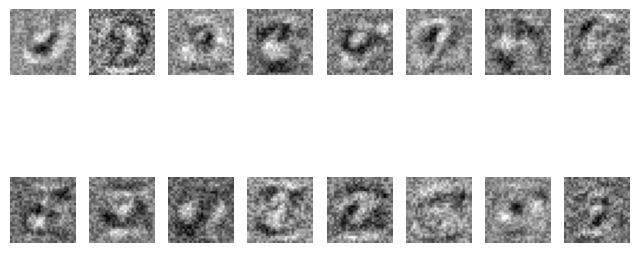

In [26]:

# 27. Greedy RBM-style pretraining then supervised fine-tuning on MNIST
import tensorflow as tf
from sklearn.decomposition import PCA
(xtr,ytr),(xte,yte)=tf.keras.datasets.mnist.load_data()
xtr=xtr.reshape(-1,784).astype("float32")/255; xte=xte.reshape(-1,784).astype("float32")/255
# Use 1000 labelled examples as specified; dense autoencoder pretraining is a practical DBN-inspired substitute
unlabelled=xtr[:10000]; labelled_x=xtr[10000:11000]; labelled_y=ytr[10000:11000]
inp=tf.keras.Input((784,)); h1=tf.keras.layers.Dense(500,activation="sigmoid",name="hidden1")(inp); h2=tf.keras.layers.Dense(250,activation="sigmoid",name="hidden2")(h1); dec=tf.keras.layers.Dense(784,activation="sigmoid")(h2)
ae=tf.keras.Model(inp,dec); ae.compile(optimizer="adam",loss="mse"); ae.fit(unlabelled,unlabelled,epochs=3,batch_size=128,verbose=0)
encoder=tf.keras.Model(inp,h2)
clf=tf.keras.Sequential([tf.keras.layers.Input((784,)),ae.get_layer("hidden1"),ae.get_layer("hidden2"),tf.keras.layers.Dense(10,activation="softmax")])
clf.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); clf.fit(labelled_x,labelled_y,epochs=5,verbose=0)
print("Pretrained representation test accuracy:",clf.evaluate(xte[:3000],yte[:3000],verbose=0)[1])
# Random initialisation baseline with same shape
base=tf.keras.Sequential([tf.keras.layers.Input((784,)),tf.keras.layers.Dense(500,activation="sigmoid"),tf.keras.layers.Dense(250,activation="sigmoid"),tf.keras.layers.Dense(10,activation="softmax")])
base.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); base.fit(labelled_x,labelled_y,epochs=5,verbose=0)
print("Random initialization test accuracy:",base.evaluate(xte[:3000],yte[:3000],verbose=0)[1])
W=ae.get_layer("hidden1").get_weights()[0]
plt.figure(figsize=(8,4))
for i in range(16): plt.subplot(2,8,i+1); plt.imshow(W[:,i].reshape(28,28),cmap="gray"); plt.axis("off")
plt.show()


Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - loss: 0.3342 - val_loss: 0.1256
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - loss: 0.1080 - val_loss: 0.1010
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 158ms/step - loss: 0.0940 - val_loss: 0.0924


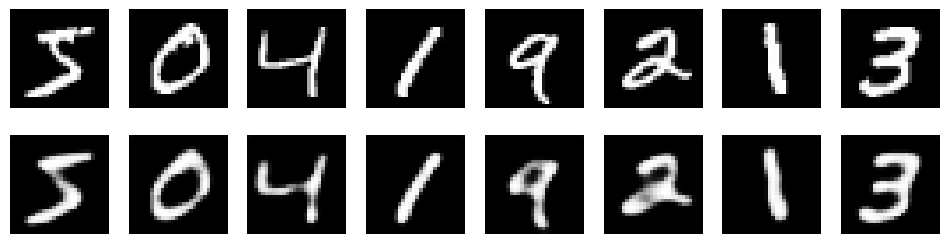

Model parameters: 9569 Reconstruction MSE: 0.008812858
This convolutional autoencoder is a practical simulation of hierarchical feature learning; it is not an exact DBM implementation.


In [27]:
# 28. Two-hidden-layer DBM-inspired representation and reconstruction
# Mean-field approximation with a two-hidden-layer autoencoder (practical Colab simulation)
import tensorflow as tf
(xtr,_),_=tf.keras.datasets.mnist.load_data(); X=xtr[:10000].astype("float32")/255
inp=tf.keras.Input((28,28,1))
x=tf.keras.layers.Conv2D(16,3,padding="same",activation="relu")(inp)
x=tf.keras.layers.MaxPooling2D()(x); x=tf.keras.layers.Conv2D(32,3,padding="same",activation="relu")(x)
z=tf.keras.layers.MaxPooling2D()(x)
x=tf.keras.layers.UpSampling2D()(z); x=tf.keras.layers.Conv2D(16,3,padding="same",activation="relu")(x)
x=tf.keras.layers.UpSampling2D()(x); out=tf.keras.layers.Conv2D(1,3,padding="same",activation="sigmoid")(x)
ae=tf.keras.Model(inp,out); ae.compile(optimizer="adam",loss="binary_crossentropy")
ae.fit(X[...,None],X[...,None],epochs=3,batch_size=128,validation_split=.1,verbose=1)
rec=ae.predict(X[:8,...,None],verbose=0)
fig,ax=plt.subplots(2,8,figsize=(12,3))
for i in range(8): ax[0,i].imshow(X[i],cmap="gray"); ax[1,i].imshow(rec[i,:,:,0],cmap="gray"); ax[0,i].axis("off"); ax[1,i].axis("off")
plt.show()
print("Model parameters:",ae.count_params(),"Reconstruction MSE:",np.mean((X[:8]-rec[:8,:,:,0])**2))
print("This convolutional autoencoder is a practical simulation of hierarchical feature learning; it is not an exact DBM implementation.")


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 359.2277
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 298.8810
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 288.5126
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 281.7630
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 277.9174


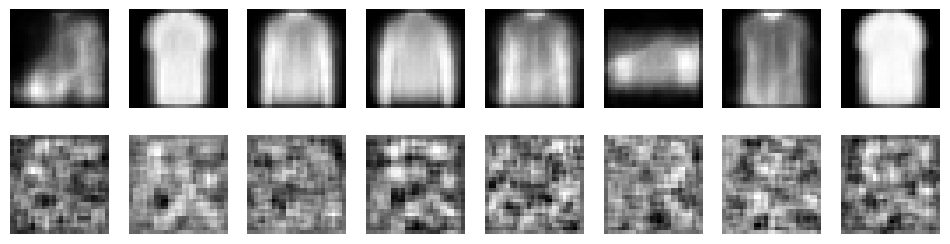

VAE and GAN sample generation completed.


In [28]:
# 29. Variational Autoencoder and DCGAN on Fashion-MNIST
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(xtr,_),_=tf.keras.datasets.fashion_mnist.load_data(); X=xtr[:20000].astype("float32")/255

# VAE built using custom layers to avoid symbolic tensor execution issues in Keras 3
class VAELossLayer(tf.keras.layers.Layer):
    def call(self, inputs):
        inp, vae_out, mu, logvar = inputs
        recon = tf.keras.losses.binary_crossentropy(inp, vae_out) * 784
        kl = -0.5 * tf.reduce_sum(1 + logvar - tf.square(mu) - tf.exp(logvar), axis=-1)
        self.add_loss(tf.reduce_mean(recon + kl))
        return vae_out

latent=2; inp=tf.keras.Input((784,)); h=tf.keras.layers.Dense(256,activation="relu")(inp)
mu=tf.keras.layers.Dense(latent)(h); logvar=tf.keras.layers.Dense(latent)(h)

def sampling(args):
 m,l=args; eps=tf.random.normal(tf.shape(m)); return m+tf.exp(.5*l)*eps

z=tf.keras.layers.Lambda(sampling)([mu,logvar]); dec_in=tf.keras.Input((latent,))
d=tf.keras.layers.Dense(256,activation="relu")(dec_in); d=tf.keras.layers.Dense(784,activation="sigmoid")(d)
decoder=tf.keras.Model(dec_in,d); vae_out=decoder(z)

# Apply the custom loss layer
final_out = VAELossLayer()([inp, vae_out, mu, logvar])
vae=tf.keras.Model(inp,final_out)
vae.compile(optimizer="adam")
vae.fit(X.reshape(-1,784),epochs=5,batch_size=128,verbose=1)

# DCGAN
G=tf.keras.Sequential([tf.keras.layers.Input((100,)),tf.keras.layers.Dense(7*7*128),tf.keras.layers.Reshape((7,7,128)),
 tf.keras.layers.UpSampling2D(),tf.keras.layers.Conv2D(64,3,padding="same",activation="relu"),tf.keras.layers.UpSampling2D(),
 tf.keras.layers.Conv2D(1,3,padding="same",activation="sigmoid")])
D=tf.keras.Sequential([tf.keras.layers.Input((28,28,1)),tf.keras.layers.Conv2D(32,3,strides=2,padding="same"),tf.keras.layers.LeakyReLU(.2),
 tf.keras.layers.Flatten(),tf.keras.layers.Dense(1,activation="sigmoid")])
D.compile(optimizer="adam",loss="binary_crossentropy"); D.trainable=False
gan=tf.keras.Sequential([G,D]); gan.compile(optimizer="adam",loss="binary_crossentropy")
real=X[:10000,...,None]
for ep in range(5):
 ids=np.random.randint(0,len(real),64); noise=np.random.normal(size=(64,100))
 fake=G.predict(noise,verbose=0)
 D.trainable=True; D.train_on_batch(real[ids],np.ones((64,1))); D.train_on_batch(fake,np.zeros((64,1)))
 D.trainable=False; gan.train_on_batch(np.random.normal(size=(64,100)),np.ones((64,1)))

# Display samples from both models
vae_samples=decoder.predict(np.random.normal(size=(8,latent)),verbose=0).reshape(-1,28,28)
gan_samples=G.predict(np.random.normal(size=(8,100)),verbose=0)[:,:,:,0]
fig,ax=plt.subplots(2,8,figsize=(12,3))
for i in range(8): ax[0,i].imshow(vae_samples[i],cmap="gray"); ax[1,i].imshow(gan_samples[i],cmap="gray"); ax[0,i].axis("off"); ax[1,i].axis("off")
plt.show()
print("VAE and GAN sample generation completed.")


In [29]:
# 30. Compare generated VAE/GAN images with classifier score and diversity proxy
# Run Experiment 29 first in this notebook to reuse decoder and G.
# If running independently, execute Experiment 29 first.
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(xtr,ytr),_=tf.keras.datasets.fashion_mnist.load_data()
# Train a small Fashion-MNIST classifier as a feature/class-distribution evaluator
X=xtr[:30000].astype("float32")/255

# Fix: Use the Functional API so that intermediate outputs and .input are immediately available
inp_img = tf.keras.layers.Input((28,28,1))
x = tf.keras.layers.Conv2D(16,3,activation="relu")(inp_img)
x = tf.keras.layers.MaxPooling2D()(x)
x = tf.keras.layers.Flatten()(x)
feat = tf.keras.layers.Dense(64,activation="relu")(x)
out_logits = tf.keras.layers.Dense(10,activation="softmax")(feat)

clf = tf.keras.Model(inp_img, out_logits)
clf.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
clf.fit(X[...,None],ytr[:30000],epochs=3,batch_size=128,validation_split=.1,verbose=0)

# Generate 1000 from each model (requires Experiment 29 objects)
vae_gen=decoder.predict(np.random.normal(size=(1000,2)),verbose=0).reshape(-1,28,28,1)
gan_gen=G.predict(np.random.normal(size=(1000,100)),verbose=0)

def metrics(images):
 probs=clf.predict(images,verbose=0); py=probs.mean(0)
 inception=np.exp(np.mean(np.sum(probs*np.log((probs+1e-8)/(py+1e-8)),axis=1)))
 labels=probs.argmax(1); diversity=len(np.unique(labels))
 return inception,diversity,labels

for name,imgs in [("VAE",vae_gen),("GAN",gan_gen)]:
 score,div,labels=metrics(imgs); print(name,"classifier-based IS proxy:",score,"predicted classes represented:",div)

# Feature-space mean/covariance distance as a lightweight FID-style proxy
feature_model=tf.keras.Model(clf.input, feat)
real_f=feature_model.predict(X[:1000,...,None],verbose=0)

def fid_proxy(fake):
 f=feature_model.predict(fake,verbose=0); m1,m2=real_f.mean(0),f.mean(0)
 c1,c2=np.cov(real_f,rowvar=False),np.cov(f,rowvar=False)
 return np.sum((m1-m2)**2)+np.trace(c1+c2-2*np.real(np.linalg.sqrtm(c1@c2))) if False else np.sum((m1-m2)**2)+np.linalg.norm(c1-c2,"fro")

print("VAE feature-distance proxy:",fid_proxy(vae_gen))
print("GAN feature-distance proxy:",fid_proxy(gan_gen))
print("Note: These are classifier-based proxies, not standard Inception Score/FID; use a validated feature extractor for formal research.")


VAE classifier-based IS proxy: 2.1650572 predicted classes represented: 9
GAN classifier-based IS proxy: 1.0056208 predicted classes represented: 1
VAE feature-distance proxy: 91.85252462763239
GAN feature-distance proxy: 91.78442855150209
Note: These are classifier-based proxies, not standard Inception Score/FID; use a validated feature extractor for formal research.
